In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

def fred(series_id):
    url = f"https://fred.stlouisfed.org/graph/fredgraph.csv?id={series_id}"
    df = pd.read_csv(url)
    df.columns = ["date", series_id]
    df["date"] = pd.to_datetime(df["date"])
    df[series_id] = pd.to_numeric(df[series_id], errors="coerce")
    return df.set_index("date")

cpi = fred("CPIAUCSL")
mich = fred("MICH")
print(cpi.tail(3))
print(mich.tail(3))


A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.4.6 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "/opt/anaconda3/lib/python3.11/site-packages/ipykernel_launcher.py", line 17, in <module>
    app.launch_new_instance()
  File "/opt/anaconda3/lib/python3.11/site-packages/traitlets/config/application.py", line 992, in launch_instance
    app.start()
  File "/opt/anaconda3/lib/python3.11/site-packages/ipykernel/kernelapp.py", line 701, in start
    self.io_loop.start()
  File "/opt/anaconda3/lib/python3.11/site-p

AttributeError: _ARRAY_API not found


A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.4.6 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "/opt/anaconda3/lib/python3.11/site-packages/ipykernel_launcher.py", line 17, in <module>
    app.launch_new_instance()
  File "/opt/anaconda3/lib/python3.11/site-packages/traitlets/config/application.py", line 992, in launch_instance
    app.start()
  File "/opt/anaconda3/lib/python3.11/site-packages/ipykernel/kernelapp.py", line 701, in start
    self.io_loop.start()
  File "/opt/anaconda3/lib/python3.11/site-p

AttributeError: _ARRAY_API not found

            CPIAUCSL
date                
2026-07-01   332.813
2026-08-01   334.131
2026-09-01   336.298
            MICH
date            
2026-07-01   4.2
2026-08-01   4.0
2026-09-01   4.6


In [2]:
cpi["cpi_yoy"] = cpi["CPIAUCSL"].pct_change(12) * 100

df = cpi[["cpi_yoy"]].join(mich.rename(columns={"MICH": "mich_expect"}), how="inner")
df = df.loc["2021-01-01":].dropna()
print(df.shape)
df.head()

(68, 2)


,cpi_yoy,mich_expect
date,,
2021-01-01,1.373844,3.0
2021-02-01,1.669817,3.3
2021-03-01,2.667819,3.1
2021-04-01,4.133077,3.4
2021-05-01,4.918257,4.6


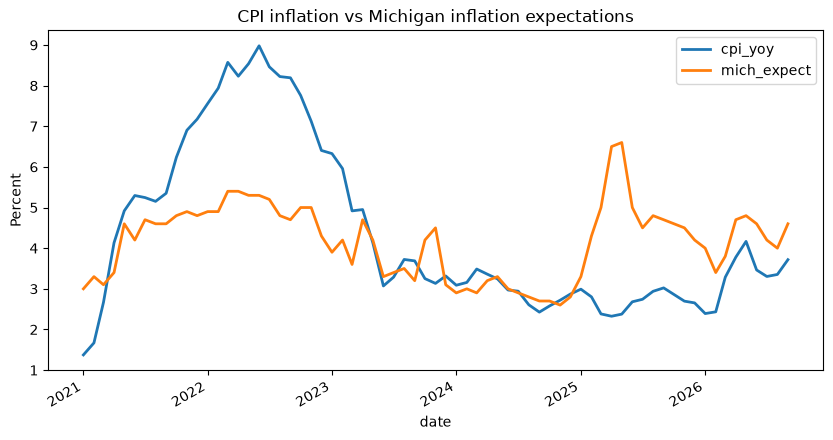

In [3]:
ax = df.plot(figsize=(10, 5), lw=2)
ax.set_title("CPI inflation vs Michigan inflation expectations")
ax.set_ylabel("Percent")
plt.show()

In [4]:
df.to_csv("../data/official.csv")
print("saved")

saved


<Axes: xlabel='date'>

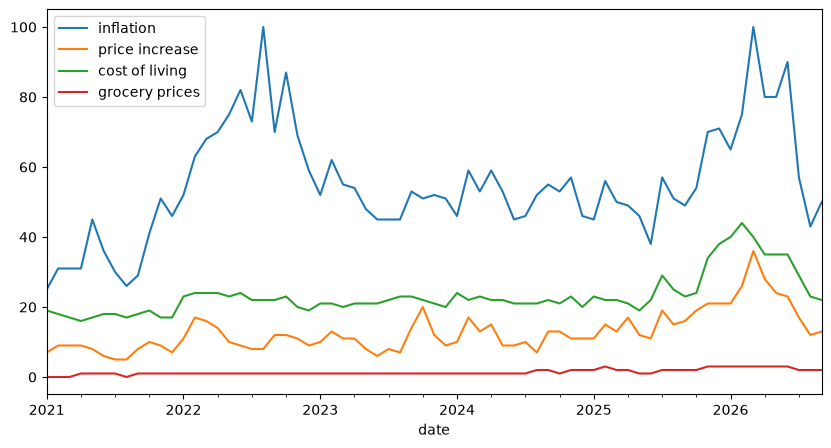

In [5]:
from pytrends.request import TrendReq
pt = TrendReq(hl="en-US", tz=360)
terms = ["inflation", "price increase", "cost of living", "grocery prices"]
pt.build_payload(terms, timeframe="2021-01-01 2026-09-30", geo="US")
trends = pt.interest_over_time().drop(columns="isPartial")
trends.to_csv("../data/trends.csv")
trends.plot(figsize=(10, 5))

<Axes: title={'center': 'Price attention index (z-score)'}, xlabel='date'>

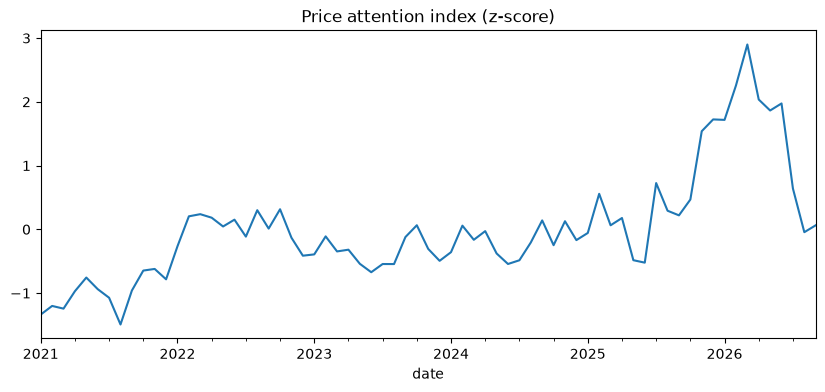

In [6]:
t = trends.copy()
t.index = pd.to_datetime(t.index)
t = t.resample("MS").mean()          # one row per month

z = (t - t.mean()) / t.std()          # z-score each term separately
t["attention"] = z.mean(axis=1)       # average into one index
t["attention"].plot(figsize=(10, 4), title="Price attention index (z-score)")

In [7]:
off = pd.read_csv("../data/official.csv", index_col=0, parse_dates=True)
d = t[["attention"]].join(off, how="inner").dropna()
print(d.shape)
d.head()

(68, 3)


,attention,cpi_yoy,mich_expect
date,,,
2021-01-01,-1.337656,1.373844,3.0
2021-02-01,-1.201930,1.669817,3.3
2021-03-01,-1.244359,2.667819,3.1
2021-04-01,-0.971071,4.133077,3.4
2021-05-01,-0.756681,4.918257,4.6


     vs_cpi  vs_mich
lag                 
0     -0.11     0.13
1     -0.14     0.16
2     -0.19     0.13
3     -0.22     0.08
4     -0.24     0.02
5     -0.25     0.01
6     -0.28     0.00


<Axes: title={'center': 'Correlation by lag (months)'}, xlabel='lag'>

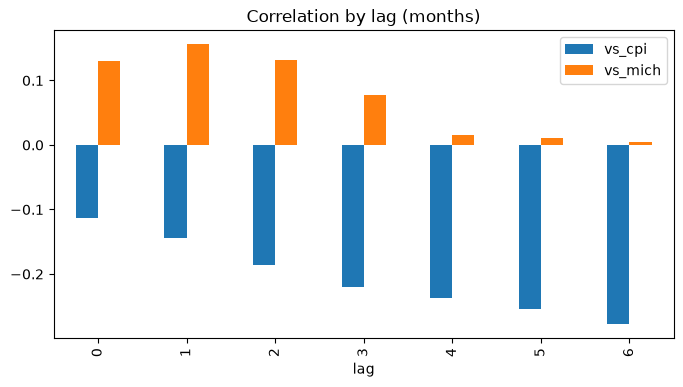

In [8]:
rows = []
for k in range(0, 7):
    rows.append({
        "lag": k,
        "vs_cpi":  d["attention"].shift(k).corr(d["cpi_yoy"]),
        "vs_mich": d["attention"].shift(k).corr(d["mich_expect"]),
    })
lags = pd.DataFrame(rows).set_index("lag")
print(lags.round(2))
lags.plot(kind="bar", figsize=(8, 4), title="Correlation by lag (months)")

In [9]:
dd = d.diff().dropna()               # month-over-month changes
rows = []
for k in range(0, 7):
    rows.append({
        "lag": k,
        "vs_cpi":  dd["attention"].shift(k).corr(dd["cpi_yoy"]),
        "vs_mich": dd["attention"].shift(k).corr(dd["mich_expect"]),
    })
print(pd.DataFrame(rows).set_index("lag").round(2))

     vs_cpi  vs_mich
lag                 
0      0.13     0.04
1      0.11     0.21
2      0.09     0.06
3     -0.01     0.02
4      0.10    -0.11
5      0.09    -0.04
6      0.12     0.14


In [10]:
for term in ["inflation","price increase","cost of living","grocery prices"]:
    s = z[term].reindex(d.index)
    print(term,
          "| levels vs CPI:", round(s.corr(d["cpi_yoy"]),2),
          "| vs Michigan:", round(s.corr(d["mich_expect"]),2),
          "| changes vs CPI:", round(s.diff().corr(d["cpi_yoy"].diff()),2))

print(d.loc[:"2023-12"].corr().round(2))   # 2021-2023 only
d.tail(12)

inflation | levels vs CPI: 0.37 | vs Michigan: 0.26 | changes vs CPI: 0.19
price increase | levels vs CPI: -0.24 | vs Michigan: 0.11 | changes vs CPI: 0.08
cost of living | levels vs CPI: -0.21 | vs Michigan: 0.02 | changes vs CPI: -0.04
grocery prices | levels vs CPI: -0.33 | vs Michigan: 0.06 | changes vs CPI: 0.11
             attention  cpi_yoy  mich_expect
attention         1.00     0.65         0.53
cpi_yoy           0.65     1.00         0.87
mich_expect       0.53     0.87         1.00


,attention,cpi_yoy,mich_expect
date,,,
2025-09-01,0.219128,3.022572,4.7
2025-11-01,1.539085,2.696444,4.5
2025-12-01,1.724157,2.653304,4.2
2026-01-01,1.716883,2.391201,4.0
2026-02-01,2.255212,2.434004,3.4
2026-03-01,2.899498,3.285958,3.8
2026-04-01,2.036151,3.779246,4.7
2026-05-01,1.864102,4.166615,4.8
2026-06-01,1.974643,3.463531,4.6


<Axes: xlabel='date'>

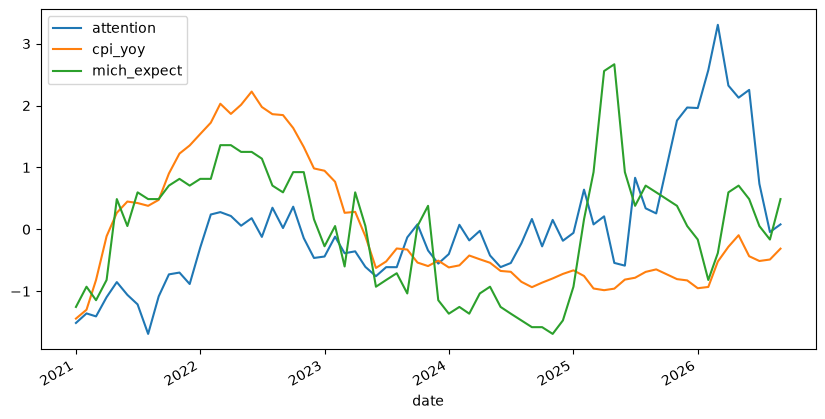

In [11]:
zz = (d - d.mean()) / d.std()
zz[["attention","cpi_yoy","mich_expect"]].plot(figsize=(10, 5))

In [12]:
full = pd.date_range("2021-01-01", "2026-09-01", freq="MS")
x = pd.DataFrame({"infl_search": z["inflation"]}).join(off).reindex(full)
print(x.isna().sum())   # expect exactly one missing month: 2025-10

def lagtable(df, col, maxlag=6, diff=False):
    a = df.diff() if diff else df
    rows = []
    for k in range(maxlag + 1):
        rows.append({"lag": k,
                     "vs_cpi":  a[col].shift(k).corr(a["cpi_yoy"]),
                     "vs_mich": a[col].shift(k).corr(a["mich_expect"])})
    return pd.DataFrame(rows).set_index("lag").round(2)

print("Levels, full sample");            print(lagtable(x, "infl_search"))
print("Changes, full sample");           print(lagtable(x, "infl_search", diff=True))
print("Changes, 2024 onward (holdout)"); print(lagtable(x.loc["2024-01-01":], "infl_search", diff=True))

infl_search    0
cpi_yoy        1
mich_expect    1
dtype: int64
Levels, full sample
     vs_cpi  vs_mich
lag                 
0      0.37     0.26
1      0.30     0.22
2      0.21     0.16
3      0.13     0.06
4      0.05    -0.03
5      0.00    -0.04
6     -0.06    -0.04
Changes, full sample
     vs_cpi  vs_mich
lag                 
0      0.22     0.15
1      0.15     0.06
2      0.09     0.07
3      0.08    -0.02
4     -0.00    -0.14
5      0.08    -0.09
6      0.19     0.36
Changes, 2024 onward (holdout)
     vs_cpi  vs_mich
lag                 
0      0.09     0.08
1      0.06     0.13
2      0.10    -0.04
3     -0.06     0.01
4     -0.03    -0.25
5      0.08    -0.04
6      0.02     0.33


In [13]:
for k in range(1, 7):
    print(k, round(x["infl_search"].corr(x["cpi_yoy"].shift(k)), 2))

1 0.39
2 0.38
3 0.35
4 0.34
5 0.39
6 0.33


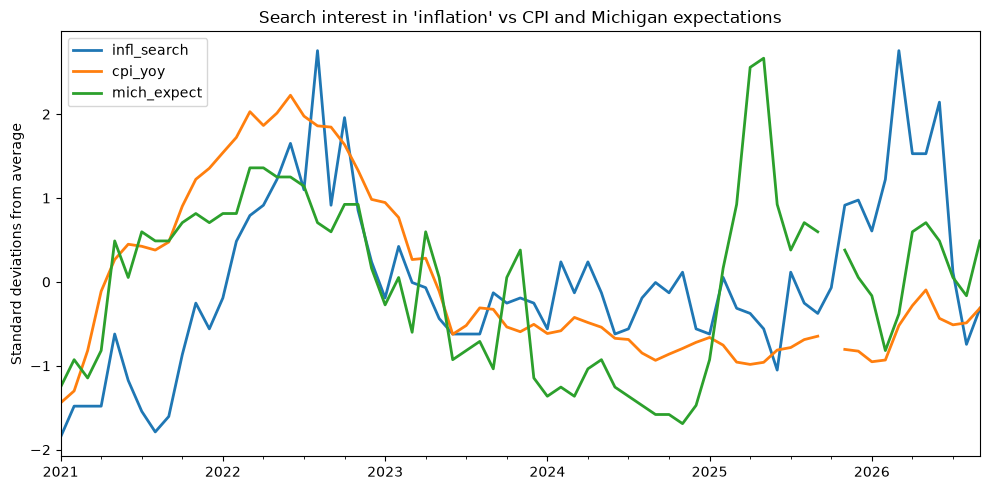

In [14]:
# Chart 1: timeline
zx = (x - x.mean()) / x.std()
ax = zx.plot(figsize=(10, 5), lw=2)
ax.set_title("Search interest in 'inflation' vs CPI and Michigan expectations")
ax.set_ylabel("Standard deviations from average")
plt.tight_layout(); plt.savefig("../charts/01_timeline.png", dpi=160); plt.show()

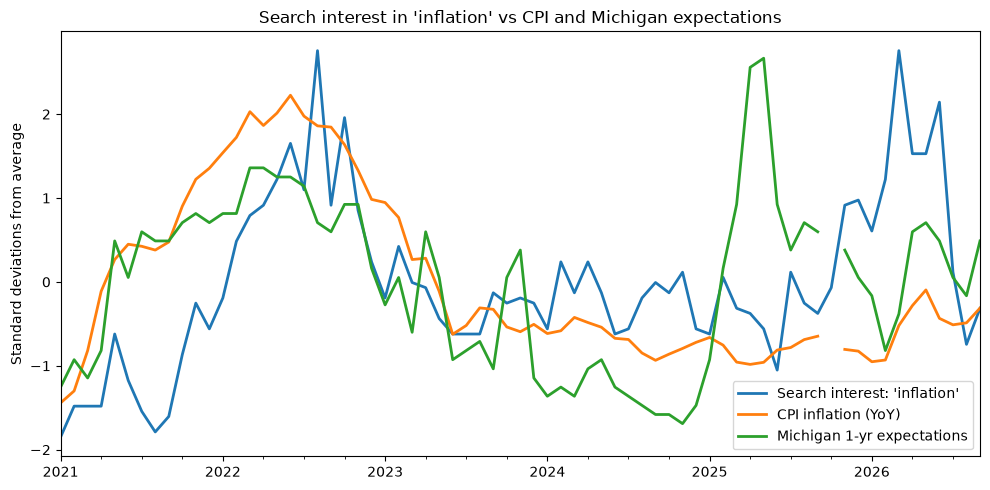

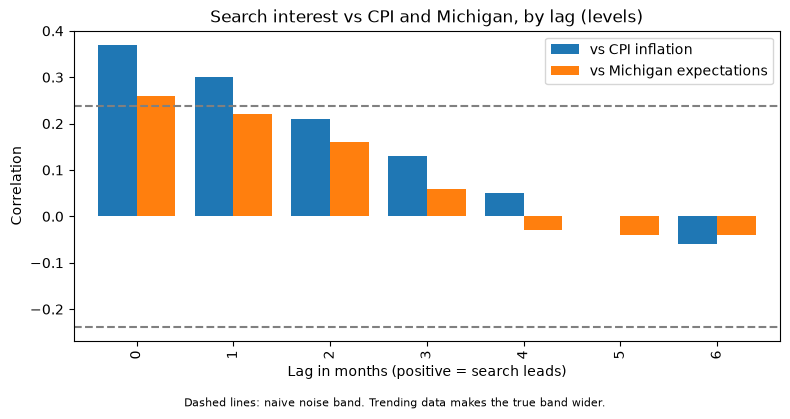

In [15]:
labels = {"infl_search": "Search interest: 'inflation'",
          "cpi_yoy": "CPI inflation (YoY)",
          "mich_expect": "Michigan 1-yr expectations"}

zx = ((x - x.mean()) / x.std()).rename(columns=labels)
ax = zx.plot(figsize=(10, 5), lw=2)
ax.set_title("Search interest in 'inflation' vs CPI and Michigan expectations")
ax.set_xlabel("")
ax.set_ylabel("Standard deviations from average")
plt.tight_layout(); plt.savefig("../charts/01_timeline.png", dpi=160); plt.show()

lt2 = lagtable(x, "infl_search").rename(
        columns={"vs_cpi": "vs CPI inflation", "vs_mich": "vs Michigan expectations"})
ax = lt2.plot(kind="bar", figsize=(8, 4), width=0.8)
band = 1.96 / np.sqrt(len(x.dropna()))
ax.axhline(band, ls="--", color="gray"); ax.axhline(-band, ls="--", color="gray")
ax.set_title("Search interest vs CPI and Michigan, by lag (levels)")
ax.set_xlabel("Lag in months (positive = search leads)")
ax.set_ylabel("Correlation")
plt.figtext(0.5, -0.03, "Dashed lines: naive noise band. Trending data makes the true band wider.",
            ha="center", fontsize=8)
plt.tight_layout(); plt.savefig("../charts/02_lags.png", dpi=160, bbox_inches="tight"); plt.show()